# 02. 가격으로 나눈 급지 사이의 선행·후행 관계

**질문:** 가격으로 분류한 급지 사이에 선행·후행 관계가 나타나는가?

**방법과 지표**
1. **급지 분류(기준연도 고정):** 2018년 거래(일괄 제외)로 구별 구성 보정 가격 수준(구 FE, 월 FE, 면적·연식·층 구간 통제)과 log ㎡당 중위가격을 구하고, 표준화해 25개 구를 k-means로 나눈다. k=2~6의 관성(엘보우)·실루엣·군집 크기를 비교한다.
   - **주 k는 실루엣 최댓값으로 미리 정한다.** 업계 관행(4~5급지)을 고려해 k=4 결과도 함께 둔다.
   - 안정성: 2018년 거래를 단지 단위로 재표본한 부트스트랩 200회의 ARI, 기준연도를 2019년으로 바꿨을 때의 ARI.
   - 군집 이름은 "가격 구간1(상)…"처럼 중립적으로 붙인다.
2. **급지 지수:** 기준연도 이후(2019-01~2026-09) 급지별로 단지 고정효과 + 면적·층 구간을 넣은 월 더미 지수를 만들고 월 변화율(log×100)을 쓴다. 월 계수의 표준오차(단지 클러스터)로 급지별 측정 잡음을 비교한다.
3. **선행·후행 검정:** ADF(수준·차분) → VAR 시차를 BIC로 선택(AIC는 민감도) → (a) 쌍별 Granger 검정(HAC 표준오차, Newey-West 4시차) (b) 모든 급지의 시차를 함께 넣은 다변량(VAR) 방정식에서 같은 HAC Wald 검정(다른 급지의 시차 통제, 주결과; statsmodels 기본 VAR Wald 검정은 민감도) → BH FDR 보정 → 잔차 Ljung-Box 점검.

**사용한 교재 장:** 7·8장 k-means, 실루엣·엘보우(급지 분류). 선행·후행 검정(ADF·Granger·VAR·FDR·HAC)은 교재 기법으로 대체할 수 없어 조율안 02의 "유지" 항목을 따른다.
**교재에서 바꾼 점과 이유:** 교재는 k를 실루엣·엘보우로 고르는 데서 끝나지만, 여기서는 군집 안정성(부트스트랩·기준연도 변경 ARI)을 추가했다. 표본이 25개 구뿐이라 분류가 작은 변화에 흔들릴 수 있기 때문이다. 가격으로 만든 급지를 이후 기간 분석에 쓰므로 순환 논리를 피하려고 기준연도(2018)를 고정하고 2019년 이후만 검정한다.

**주의:** Granger 검정은 "한 계열의 과거 값이 다른 계열의 예측에 도움이 되는가"를 보는 통계적 연관이다. "상급지가 하급지를 끌어올린다" 같은 인과로 읽지 않는다. 급지마다 포함된 구·거래 수가 달라 측정 잡음이 다르고, 잡음이 큰 계열은 선행·후행 판정을 왜곡할 수 있다.

**코드 수준:** 계수(크기)만 필요한 단계는 pandas 평균 빼기와 `LinearRegression`으로 쓴 쉬운 함수(`ru.easy_index`, `ru.easy_dong_level` 등)를 쓴다. 원래 함수와 값이 같다(차이 1e-8 이하). 표준오차·검정·부트스트랩이 필요한 단계는 기존 재검증 코드를 그대로 쓴다. 이 노트북에서 쉬운 버전으로 바꾼 곳: 구별 보정 가격 수준(군집 특징). 급지 지수(월 변화 표준오차 필요), ADF·Granger·VAR 검정은 원래 코드를 쓴다.


In [1]:
import os
import sys
from pathlib import Path


def _find_root():
    env = os.environ.get("REANALYSIS_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "AGENTS.md").exists():
            return p
    raise FileNotFoundError("AGENTS.md가 있는 프로젝트 루트를 찾지 못했습니다")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src" / "재검증"))
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import reanalysis_utils as ru

SEED = ru.SEED
DATA = ROOT / "data"
plt = ru.set_korean_font()

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR
from statsmodels.stats.diagnostic import acorr_ljungbox
import statsmodels.api as sm

OUT = ru.out_dir(ROOT, "02")
tx = ru.load_tx(ROOT)
nob = tx[tx["in_base_nobulk"]].reset_index(drop=True)
BASE_YEAR = 2018
ANALYSIS = ru.ym_range("2019-01", "2026-09")


def gu_features(d):
    """구별 보정 가격 수준(동 대신 구를 키로 dong_level 재사용)과 log 중위가격."""
    dd = d.assign(dong_id=d["gu"])
    lev, _ = ru.easy_dong_level(dd)
    lev = lev.rename(columns={"dong_id": "gu"}).set_index("gu")
    lev["log_median"] = np.log(d.groupby("gu")["ppa_manwon"].median())
    return lev[["adj_log_level", "log_median", "n_tx"]]


f18 = gu_features(nob[nob["contract_year"] == BASE_YEAR])
f19 = gu_features(nob[nob["contract_year"] == BASE_YEAR + 1])
f18.sort_values("adj_log_level", ascending=False).round(3).head(8)

,adj_log_level,log_median,n_tx
gu,,,
강남구,0.755,7.402,3528
서초구,0.600,7.158,3104
용산구,0.424,7.042,1714
송파구,0.412,6.967,4548
성동구,0.282,6.914,2792
광진구,0.238,6.873,1458
마포구,0.236,6.860,2910
동작구,0.160,6.760,2710


`adj_log_level`은 2018년 같은 면적·연식·층 구성으로 맞춘 구별 log ㎡당 가격 수준(거래 가중 평균=0), `log_median`은 단순 log 중위가격이다. 두 값을 표준화해 k-means 입력으로 쓴다.

In [3]:
FEATS = ["adj_log_level", "log_median"]
Xs = StandardScaler().fit_transform(f18[FEATS])
krows = []
labels_by_k = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Xs)
    labels_by_k[k] = km.labels_
    sizes = np.bincount(km.labels_)
    krows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xs, km.labels_),
                  "min_size": sizes.min(), "sizes": "-".join(map(str, sorted(sizes, reverse=True)))})
kt = pd.DataFrame(krows)
K_MAIN = int(kt.loc[kt["silhouette"].idxmax(), "k"])
kt

,k,inertia,silhouette,min_size,sizes
0,2,15.512587,0.571610,11,14-11
1,3,7.695443,0.512837,4,11-10-4
2,4,4.230878,0.519071,2,10-8-5-2
3,5,2.685400,0.460355,2,7-6-5-5-2
4,6,1.762998,0.512697,2,6-5-4-4-4-2


In [4]:
def relabel(labels, level):
    """군집을 평균 가격 수준이 높은 순서로 1, 2, …로 다시 번호 붙인다."""
    order = pd.Series(level).groupby(labels).mean().sort_values(ascending=False).index
    m = {old: i + 1 for i, old in enumerate(order)}
    return np.array([m[l] for l in labels])


def boot_features(B=200):
    """2018년 거래를 단지 단위로 재표본해 구별 특징을 B번 다시 계산한다."""
    d18 = nob[nob["contract_year"] == BASE_YEAR]
    cx = d18["complex_id"].unique()
    rng = np.random.default_rng(SEED)
    by_cx = {c: g.index.to_numpy() for c, g in d18.groupby("complex_id")}
    out = []
    for _ in range(B):
        pick = rng.choice(cx, size=len(cx), replace=True)
        idx = np.concatenate([by_cx[c] for c in pick])
        out.append(gu_features(d18.loc[idx].reset_index(drop=True)).reindex(f18.index))
    return out


BOOT = boot_features()


def boot_ari(k):
    aris = []
    for fb in BOOT:
        sc = StandardScaler().fit(fb[FEATS])
        lab = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(sc.transform(fb[FEATS]))
        aris.append(adjusted_rand_score(labels_by_k[k], lab))
    return np.array(aris)


stab = []
for k in sorted({K_MAIN, 3, 4}):
    a = boot_ari(k)
    lab19 = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(
        StandardScaler().fit_transform(f19.reindex(f18.index)[FEATS]))
    stab.append({"k": k, "boot_ari_mean": a.mean(), "boot_ari_p05": np.percentile(a, 5),
                 "boot_ari_p95": np.percentile(a, 95), "ari_base2019_vs_2018": adjusted_rand_score(labels_by_k[k], lab19)})
stab = pd.DataFrame(stab)
kt = kt.merge(stab, on="k", how="left")
stab

,k,boot_ari_mean,boot_ari_p05,boot_ari_p95,ari_base2019_vs_2018
0,2,0.789314,0.553822,1.0,0.693006
1,3,0.689182,0.400892,1.0,1.000000
2,4,0.679778,0.301771,1.0,0.720054


위 표에서 `boot_ari_mean`이 1에 가까울수록 단지 재표본에도 같은 분류가 다시 나온다는 뜻이다. `ari_base2019_vs_2018`은 기준연도를 2019년으로 바꿨을 때의 일치도다.

In [5]:
groups = f18.copy()
for k in sorted({K_MAIN, 4}):
    groups[f"tier_k{k}"] = relabel(labels_by_k[k], f18["adj_log_level"].to_numpy())
groups = groups.reset_index()
groups["base_year"] = BASE_YEAR
groups.sort_values("adj_log_level", ascending=False)[["gu", "adj_log_level", "log_median", "n_tx"] +
                                                    [c for c in groups.columns if c.startswith("tier_k")]].round(3)

,gu,adj_log_level,log_median,n_tx,tier_k2,tier_k4
0,강남구,0.755,7.402,3528,1,1
14,서초구,0.600,7.158,3104,1,1
20,용산구,0.424,7.042,1714,1,2
17,송파구,0.412,6.967,4548,1,2
15,성동구,0.282,6.914,2792,1,2
5,광진구,0.238,6.873,1458,1,2
12,마포구,0.236,6.860,2910,1,2
11,동작구,0.160,6.760,2710,1,3
19,영등포구,0.082,6.693,3307,1,3
23,중구,0.079,6.749,1258,1,3


급지 번호는 2018년 보정 가격 수준의 군집 평균이 높은 순서다(1=가장 높음). 이 분류는 **2018년 가격 기준의 분석용 구분**이며 현재 서열과 다를 수 있다.

## 2. 급지별 월 지수(2019-01~2026-09)

In [6]:
def tier_indices(kcol):
    mp = groups.set_index("gu")[kcol]
    out = []
    d = nob[nob["contract_ym"].isin(ANALYSIS)].copy()
    d["tier"] = d["gu"].map(mp)
    for t, g in d.groupby("tier"):
        gi, gr = ru.time_dummy_index(g.reset_index(drop=True), ANALYSIS, fe="complex_id",
                                     char_refs=ru.CHAR_REFS_NOAGE, cluster="complex_id")
        V = gr["vcov"]
        # 월 변화(log)의 표준오차: Var(b_t − b_{t−1})
        se_d = [np.nan]
        for i in range(1, len(ANALYSIS)):
            a, b = f"m={ANALYSIS[i - 1]}", f"m={ANALYSIS[i]}"
            v = V.loc[b, b] + (V.loc[a, a] - 2 * V.loc[a, b] if i > 1 else 0)
            se_d.append(np.sqrt(v) * 100)
        gi["ret"] = gi["log_index"].diff() * 100
        gi["ret_se"] = se_d
        gi["tier"] = int(t)
        gi["n_gu"] = int((mp == t).sum())
        out.append(gi)
    return pd.concat(out, ignore_index=True)


tidx = {k: tier_indices(f"tier_k{k}") for k in sorted({K_MAIN, 4})}
noise = pd.concat([v.assign(k=k) for k, v in tidx.items()]).groupby(["k", "tier"]).agg(
    n_gu=("n_gu", "first"), tx_per_month=("n", "median"), ret_sd=("ret", "std"), ret_se_median=("ret_se", "median"))
noise["noise_share"] = (noise["ret_se_median"] ** 2) / (noise["ret_sd"] ** 2)
noise.round(3)

n_gu  tx_per_month  ret_sd  ret_se_median  noise_share
k tier                                                        
2 1       11        1726.0   2.027          0.389        0.037
  2       14        2181.0   1.799          0.296        0.027
4 1        2         360.0   2.657          0.905        0.116
  2        5         707.0   2.219          0.544        0.060
  3        8        1152.0   1.948          0.443        0.052
  4       10        1670.0   1.877          0.331        0.031

`ret_sd`는 월 변화율(log×100)의 표준편차, `ret_se_median`은 월 변화율 추정치 자체의 표준오차 중앙값(측정 잡음)이다. `noise_share`는 변화율 분산 가운데 측정 잡음이 차지하는 대략의 비율이다. 이 값이 급지마다 다르면, 잡음이 큰 계열이 Granger 검정에서 "후행"처럼 보일 수 있다.

In [7]:
def adf_table(k):
    rows = []
    for t, g in tidx[k].groupby("tier"):
        lv = g["log_index"].to_numpy()
        rt = g["ret"].dropna().to_numpy()
        a1 = adfuller(lv, regression="ct", autolag="AIC")
        a2 = adfuller(rt, regression="c", autolag="AIC")
        rows.append({"k": k, "tier": t, "adf_level_ct_p": a1[1], "adf_diff_c_p": a2[1]})
    return pd.DataFrame(rows)


adf = pd.concat([adf_table(k) for k in tidx], ignore_index=True)
adf.round(4)

,k,tier,adf_level_ct_p,adf_diff_c_p
0,2,1,0.6383,0.0000
1,2,2,0.6460,0.0003
2,4,1,0.6729,0.0000
3,4,2,0.7314,0.0000
4,4,3,0.4064,0.0172
5,4,4,0.7260,0.0000


수준(추세 포함)에서는 단위근을 기각하지 못하고, 월 변화율에서는 기각하면 변화율로 검정하는 것이 맞다. 아래 검정은 모두 월 변화율(log×100)로 한다.

## 3. Granger 검정

In [8]:
def ret_wide(k):
    w = tidx[k].pivot_table(index="month", columns="tier", values="ret").dropna()
    w.columns = [f"T{c}" for c in w.columns]
    return w


def lag_select(w, maxlags=6):
    sel = VAR(w.reset_index(drop=True)).select_order(maxlags=maxlags)
    return int(max(sel.selected_orders["bic"], 1)), int(max(sel.selected_orders["aic"], 1))


def pairwise_granger(w, p, hac_lags=4):
    rows = []
    for y in w.columns:
        for x in w.columns:
            if x == y:
                continue
            df = pd.DataFrame({"y": w[y]})
            for l in range(1, p + 1):
                df[f"y_l{l}"] = w[y].shift(l)
                df[f"x_l{l}"] = w[x].shift(l)
            df = df.dropna()
            X = sm.add_constant(df.drop(columns="y"))
            m_hac = sm.OLS(df["y"], X).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
            m_ols = sm.OLS(df["y"], X).fit()
            R = [f"x_l{l}" for l in range(1, p + 1)]
            w_hac = m_hac.wald_test(" = 0, ".join(R) + " = 0", scalar=True)
            f_ols = m_ols.f_test(" = 0, ".join(R) + " = 0")
            lb = acorr_ljungbox(m_ols.resid, lags=[12], return_df=True)["lb_pvalue"].iloc[0]
            rows.append({"cause": x, "effect": y, "lags": p, "n": int(m_ols.nobs),
                         "p_hac": float(w_hac.pvalue), "p_ols": float(f_ols.pvalue), "lb12_p": float(lb),
                         "sum_x_coef": float(m_hac.params[R].sum())})
    return pd.DataFrame(rows)


def var_granger(w, p, hac_lags=4):
    """다변량(모든 급지의 시차를 넣은 VAR 방정식) Granger 검정.

    주결과 p_varhac: 각 결과 급지 방정식을 OLS로 추정하고 Newey-West HAC(4시차) 공분산으로 원인 급지 시차들의 Wald 검정.
    민감도 p_var_default: statsmodels VAR 기본 Wald 검정(동분산·무상관 가정).
    """
    res = VAR(w.reset_index(drop=True)).fit(p)
    lagged = pd.DataFrame(index=w.index)
    for c in w.columns:
        for l in range(1, p + 1):
            lagged[f"{c}_l{l}"] = w[c].shift(l)
    rows = []
    for y in w.columns:
        df = pd.concat([w[[y]].rename(columns={y: "y"}), lagged], axis=1).dropna()
        m_hac = sm.OLS(df["y"], sm.add_constant(df.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
        for x in w.columns:
            if x == y:
                continue
            R = [f"{x}_l{l}" for l in range(1, p + 1)]
            wt = m_hac.wald_test(" = 0, ".join(R) + " = 0", scalar=True)
            t = res.test_causality(y, [x], kind="wald")
            rows.append({"cause": x, "effect": y, "lags": p, "p_varhac": float(wt.pvalue), "p_var_default": float(t.pvalue)})
    lb = [acorr_ljungbox(res.resid[c], lags=[12], return_df=True)["lb_pvalue"].iloc[0] for c in w.columns]
    return pd.DataFrame(rows), dict(zip(w.columns, lb)), res


gr_all = []
lagsel = []
for k in tidx:
    w = ret_wide(k)
    p_bic, p_aic = lag_select(w)
    lagsel.append({"k": k, "p_bic": p_bic, "p_aic": p_aic, "T": len(w)})
    for spec, p in [("BIC", p_bic), ("AIC", p_aic)]:
        pw = pairwise_granger(w, p)
        vg, lbv, _ = var_granger(w, p)
        m = pw.merge(vg, on=["cause", "effect", "lags"])
        m["var_resid_lb12_p_effect"] = m["effect"].map(lbv)
        m["k"], m["lag_spec"] = k, spec
        gr_all.append(m)
gr = pd.concat(gr_all, ignore_index=True)
for col in ["p_hac", "p_varhac", "p_var_default"]:
    gr["q_" + col[2:]] = gr.groupby(["k", "lag_spec"])[col].transform(lambda s: ru.bh_fdr(s.to_numpy()))
pd.DataFrame(lagsel)

,k,p_bic,p_aic,T
0,2,1,5,92
1,4,1,5,92


In [9]:
show = gr[(gr["k"] == K_MAIN)][["lag_spec", "cause", "effect", "lags", "n", "p_hac", "q_hac", "p_varhac", "q_varhac", "q_var_default",
                                 "lb12_p", "var_resid_lb12_p_effect", "sum_x_coef"]]
show.round(4)

,lag_spec,cause,effect,lags,n,p_hac,q_hac,p_varhac,q_varhac,q_var_default,lb12_p,var_resid_lb12_p_effect,sum_x_coef
0,BIC,T2,T1,1,91,0.0355,0.0711,0.0355,0.0711,0.0334,0.1160,0.1160,0.4156
1,BIC,T1,T2,1,91,0.0765,0.0765,0.0765,0.0765,0.0649,0.2784,0.2784,0.2325
2,AIC,T2,T1,5,87,0.0317,0.0317,0.0317,0.0317,0.0576,0.7388,0.7388,0.5647
3,AIC,T1,T2,5,87,0.0096,0.0191,0.0096,0.0191,0.0155,0.8525,0.8525,-0.2862


- `p_hac`/`q_hac`: 쌍별 Granger(자기 시차 + 상대 시차, HAC 표준오차)의 p값과 BH 보정 q값.
- `p_varhac`/`q_varhac`(**주결과**): 모든 급지의 과거 값을 함께 넣은 다변량(VAR) 방정식에서 한 급지의 과거가 다른 급지를 예측하는지에 대한 Wald 검정. 쌍별 검정과 같은 Newey-West HAC(4시차) 공분산과 같은 BH FDR 규칙을 쓴다. "다른 급지의 시차 통제"이며, 관측되지 않은 서울 공통요인을 직접 통제하는 것은 아니다. **k=2에서는 급지가 둘뿐이라 다변량 방정식이 쌍별 방정식과 같아, 추가로 통제되는 급지가 없다(두 결과가 같다).**
- `q_var_default`(민감도): statsmodels VAR 기본 Wald 검정(잔차 이분산·자기상관을 고려하지 않음)의 BH q값.
- `lb12_p`, `var_resid_lb12_p_effect`: 잔차 Ljung-Box(12시차) p값. 0.05 미만이면 잔차 자기상관이 남아 있어 해당 결과를 약하게 본다.
- `sum_x_coef`: 상대 급지 시차 계수의 합(부호 참고용).

In [10]:
if 4 != K_MAIN:
    display(gr[(gr["k"] == 4)][["lag_spec", "cause", "effect", "lags", "p_hac", "q_hac", "p_varhac", "q_varhac", "q_var_default", "lb12_p"]].round(4))

,lag_spec,cause,effect,lags,p_hac,q_hac,p_varhac,q_varhac,q_var_default,lb12_p
4,BIC,T2,T1,1,0.0003,0.0011,0.1737,0.4169,0.4761,0.3564
5,BIC,T3,T1,1,0.0000,0.0001,0.0067,0.0285,0.0268,0.3343
6,BIC,T4,T1,1,0.0526,0.0790,0.4858,0.5572,0.4935,0.2260
7,BIC,T1,T2,1,0.3407,0.3407,0.2815,0.5270,0.4251,0.7166
8,BIC,T3,T2,1,0.0174,0.0352,0.0337,0.1011,0.0766,0.3990
9,BIC,T4,T2,1,0.1204,0.1605,0.3643,0.5270,0.4935,0.5069
10,BIC,T1,T3,1,0.1702,0.2042,0.5107,0.5572,0.4849,0.1627
11,BIC,T2,T3,1,0.0223,0.0383,0.3730,0.5270,0.4251,0.2139
12,BIC,T4,T3,1,0.0051,0.0154,0.0071,0.0285,0.0009,0.7940
13,BIC,T1,T4,1,0.2843,0.3101,0.3953,0.5270,0.4935,0.4642


## 4. 교차상관(서술용)

In [11]:
w = ret_wide(K_MAIN)
top, bottom = w.columns[0], w.columns[-1]
ccf_rows = []
for kcol in w.columns[1:]:
    for lag in range(-6, 7):
        ccf_rows.append({"pair": f"{top}-{kcol}", "lag": lag, "corr": w[top].corr(w[kcol].shift(-lag))})
ccf = pd.DataFrame(ccf_rows)
ccf.pivot_table(index="lag", columns="pair", values="corr").round(3)

pair,T1-T2
lag,
-6,0.105
-5,0.114
-4,0.120
-3,0.189
-2,0.273
-1,0.562
0,0.825
1,0.615
2,0.290


`lag`>0은 최상위 구간(T1)의 변화가 다른 구간의 `lag`개월 뒤 변화와 갖는 상관이다(T1이 앞섬). 0 근처가 가장 크면 같은 달에 함께 움직인 것이다. 표본 상관의 대략 95% 범위는 ±2/√T(T=검정에 쓴 월 수)이다.

In [12]:
HM_K = 4
hm = gr[(gr["k"] == HM_K) & (gr["lag_spec"] == "BIC")].pivot_table(index="cause", columns="effect", values="q_varhac")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(hm.to_numpy(), cmap="viridis_r", vmin=0, vmax=1)
ax.set_xticks(range(hm.shape[1]))
ax.set_xticklabels(hm.columns)
ax.set_yticks(range(hm.shape[0]))
ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.to_numpy()[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="w" if v < 0.5 else "k", fontsize=9)
ax.set_xlabel("결과 급지(effect)")
ax.set_ylabel("원인 후보 급지(cause)")
ax.set_title(f"다변량 Granger(HAC) BH q값 (k={HM_K}, BIC 시차, 2019-01~2026-09)", fontsize=10)
fig.colorbar(im, ax=ax, label="q값")
fig.tight_layout()
ru.save_png(fig, OUT, "fig_granger_heatmap.png")
plt.close(fig)

## 5. 저장

In [13]:
groups.to_csv(OUT / "gu_groups.csv", index=False, encoding="utf-8-sig")
ru.save_chart_csv(kt, OUT, "fig_k_selection.csv")
tid = pd.concat([v.assign(k=k) for k, v in tidx.items()], ignore_index=True)
ru.save_chart_csv(tid[["k", "tier", "n_gu", "month", "index", "log_index", "se", "ret", "ret_se", "n"]], OUT, "fig_tier_index.csv")
ru.save_chart_csv(gr, OUT, "fig_granger_heatmap.csv")
ru.save_chart_csv(ccf, OUT, "fig_ccf.csv")
ru.save_chart_csv(adf, OUT, "table_adf.csv")
ru.save_chart_csv(noise.reset_index(), OUT, "table_tier_noise.csv")

n_an = int(nob["contract_ym"].isin(ANALYSIS).sum())
n18 = int((nob["contract_year"] == BASE_YEAR).sum())
rows = []


def add(key, label, value, unit, n, ps, pe, note, src, claim="통계적 연관"):
    rows.append({"key": key, "label": label, "value": float(value), "unit": unit, "sample_n": int(n),
                 "period": f"{ps}~{pe}", "period_start": ps, "period_end": pe, "split_type": "없음",
                 "claim_level": claim, "source_file": src, "note": note})


ktm = kt.set_index("k")
add("k_main", "실루엣 기준 주 k", K_MAIN, "개", 25, "2018-01", "2018-12", "k=2~6 중 실루엣 최댓값(사전 규칙)", "fig_k_selection.csv", "단순 변화")
add("silhouette_k_main", f"k={K_MAIN} 실루엣 점수", ktm.loc[K_MAIN, "silhouette"], "점수", 25, "2018-01", "2018-12", f"구 25개, 2018년 거래 {n18:,}건", "fig_k_selection.csv", "단순 변화")
add("silhouette_k4", "k=4 실루엣 점수", ktm.loc[4, "silhouette"], "점수", 25, "2018-01", "2018-12", "업계 관행 비교용", "fig_k_selection.csv", "단순 변화")
add("boot_ari_k_main", f"k={K_MAIN} 단지 부트스트랩 ARI 평균", ktm.loc[K_MAIN, "boot_ari_mean"], "ARI", n18, "2018-01", "2018-12",
    f"200회, 5~95% {ktm.loc[K_MAIN, 'boot_ari_p05']:.2f}~{ktm.loc[K_MAIN, 'boot_ari_p95']:.2f}", "fig_k_selection.csv", "단순 변화")
add("ari_2019_vs_2018_k_main", f"k={K_MAIN} 기준연도 2019 vs 2018 ARI", ktm.loc[K_MAIN, "ari_base2019_vs_2018"], "ARI", 25, "2018-01", "2019-12",
    "기준연도 변경 민감도", "fig_k_selection.csv", "단순 변화")
bic = gr[(gr["k"] == K_MAIN) & (gr["lag_spec"] == "BIC")]
for kk in tidx:
    for spec in ["BIC", "AIC"]:
        sub_ = gr[(gr["k"] == kk) & (gr["lag_spec"] == spec)]
        add(f"granger_varhac_n_sig_q05_k{kk}_{spec}", f"다변량 HAC Granger q<0.05인 방향 수(k={kk}, {spec})", int((sub_["q_varhac"] < 0.05).sum()), "개", n_an,
            "2019-01", "2026-09", f"전체 {len(sub_)}개 방향 중, 시차 {int(sub_['lags'].iloc[0])}. 기본 VAR 검정(민감도) {int((sub_['q_var_default'] < 0.05).sum())}개"
            + (". k=2는 쌍별 검정과 같음" if kk == 2 else ""), "fig_granger_heatmap.csv")
add("granger_pair_n_sig_q05", f"쌍별 HAC Granger q<0.05인 방향 수(k={K_MAIN}, BIC)", int((bic["q_hac"] < 0.05).sum()), "개", n_an, "2019-01", "2026-09",
    f"전체 {len(bic)}개 방향 중", "fig_granger_heatmap.csv")
for kk in tidx:
    for spec in ["BIC", "AIC"]:
        sub_ = gr[(gr["k"] == kk) & (gr["lag_spec"] == spec)]
        for _, r in sub_.iterrows():
            add(f"granger_varhac_q_k{kk}_{spec}_{r['cause']}_to_{r['effect']}", f"다변량 HAC Granger q값 k={kk} {spec} {r['cause']}→{r['effect']}",
                r["q_varhac"], "q값", n_an, "2019-01", "2026-09",
                f"시차 {int(r['lags'])}, p={r['p_varhac']:.4f}, 쌍별 HAC q={r['q_hac']:.4f}, 기본 VAR q(민감도)={r['q_var_default']:.4f}, 잔차 LB12 p={r['var_resid_lb12_p_effect']:.3f}",
                "fig_granger_heatmap.csv")
c0 = ccf[ccf["lag"] == 0]
for _, r in c0.iterrows():
    add(f"ccf0_{r['pair']}", f"같은 달 변화율 상관 {r['pair']}", r["corr"], "상관계수", n_an, "2019-01", "2026-09", "월 변화율(log×100)", "fig_ccf.csv")
for (kk, t), r in noise.iterrows():
    add(f"noise_share_k{kk}_T{t}", f"k={kk} 구간{t} 월 변화율 분산 중 측정 잡음 비율", r["noise_share"], "비율", n_an, "2019-01", "2026-09",
        f"구 {int(r['n_gu'])}개, 월 거래 중앙값 {r['tx_per_month']:.0f}건", "table_tier_noise.csv", "단순 변화")
summary = ru.save_summary(rows, OUT)
ru.save_meta({
    "question": "가격으로 분류한 급지 사이에 선행·후행 관계가 나타나는가?",
    "method": "2018년 기준 구별 보정 가격으로 k-means(k=2~6, 실루엣·엘보우, 부트스트랩·기준연도 ARI) → 급지별 단지FE 월 지수(2019-01~2026-09) → ADF, VAR 시차(BIC/AIC), 쌍별 HAC Granger, 다변량 HAC Granger(주), 기본 VAR Wald(민감도), BH FDR, Ljung-Box",
    "textbook_chapters": ["7장 k-means", "8장 실루엣·엘보우·지도 시각화"],
    "sample_period": "분류 2018-01~2018-12, 검정 2019-01~2026-09",
    "sample_size": {"base_year_tx": n18, "analysis_tx": n_an, "gu": 25},
    "data_files": ["outputs/재검증/00_정제/transactions.parquet"],
    "limitations": ["2018년은 취소 정보가 없는 기간", "급지마다 구·거래 수가 달라 측정 잡음이 다르다(table_tier_noise.csv)",
                    "Granger는 예측상의 선후 관계이며 인과가 아니다", "2026-08~09는 잠정 월", "25개 구라 군집 표본이 작다",
                    "급지는 2018년 가격 기준 분석용 구분이며 현재 서열과 다를 수 있다"],
}, OUT)
summary[["key", "value", "note"]].head(20)

,key,value,note
0,k_main,2.000000,k=2~6 중 실루엣 최댓값(사전 규칙)
1,silhouette_k_main,0.571610,"구 25개, 2018년 거래 81,073건"
2,silhouette_k4,0.519071,업계 관행 비교용
3,boot_ari_k_main,0.789314,"200회, 5~95% 0.55~1.00"
4,ari_2019_vs_2018_k_main,0.693006,기준연도 변경 민감도
5,granger_varhac_n_sig_q05_k2_BIC,0.000000,"전체 2개 방향 중, 시차 1. 기본 VAR 검정(민감도) 1개. k=2는 쌍별 검..."
6,granger_varhac_n_sig_q05_k2_AIC,2.000000,"전체 2개 방향 중, 시차 5. 기본 VAR 검정(민감도) 1개. k=2는 쌍별 검..."
7,granger_varhac_n_sig_q05_k4_BIC,3.000000,"전체 12개 방향 중, 시차 1. 기본 VAR 검정(민감도) 3개"
8,granger_varhac_n_sig_q05_k4_AIC,11.000000,"전체 12개 방향 중, 시차 5. 기본 VAR 검정(민감도) 8개"
9,granger_pair_n_sig_q05,0.000000,전체 2개 방향 중


## 결론
- **급지 분류(단순 변화):** 2018년 구별 보정 가격으로 k=2~6을 비교한 결과 실루엣은 k=2가 0.572로 가장 높았고, k=4는 0.519, k=3은 0.513이었다(`fig_k_selection.csv`). 사전 규칙에 따라 주 k는 2이고, k=4를 함께 보고한다. 단지 부트스트랩 ARI 평균은 k=2 0.79, k=4 0.68이며, 기준연도를 2019년으로 바꾸면 ARI가 k=2 0.69, k=4 0.72였다. **분류 경계에 있는 몇 개 구는 표본·기준연도에 따라 소속이 바뀐다.**
- **같은 달 동조(단순 변화):** k=2에서 두 가격 구간의 월 변화율은 같은 달 상관이 0.82로 가장 높고, 앞뒤 1개월 상관(0.62, 0.56)은 비슷한 크기였다(`fig_ccf.csv`). 한쪽이 뚜렷하게 앞서는 모양은 아니다.
- **Granger(통계적 연관, 주결과는 HAC Wald + BH FDR):** k=2에서는 급지가 둘뿐이라 다변량 방정식이 쌍별 방정식과 같고, 추가로 통제되는 급지나 공통요인이 없다. BIC 시차(1)에서는 어느 방향도 q<0.05가 아니었다(T2→T1 q=0.071, T1→T2 q=0.077). AIC 시차(5)에서는 **양방향 모두** q<0.05였다(T2→T1 q=0.032, T1→T2 q=0.019). 기본 VAR Wald 검정(민감도)으로는 BIC에서 T2→T1만 q=0.033이었다(`fig_granger_heatmap.csv`).
- k=4(BIC)에서 다른 급지의 시차를 함께 통제한 다변량 HAC 검정은 T3→T1(q=0.029), T4→T3(q=0.029), T3→T4(q=0.024)가 q<0.05였다. 즉 중·하위 구간 사이에서는 양방향 관계가 나타났다. 같은 k=4의 쌍별 검정에서 유의했던 T2→T1(쌍별 q=0.001)은 다른 급지 시차를 통제하면 q=0.42로 사라졌다. 쌍별 유의성의 일부는 다른 급지의 움직임과 겹친 것으로 볼 수 있다.
- k=4 AIC 시차(5)에서는 12개 방향 중 11개가 q<0.05였다. 그러나 87개월 표본에 방정식당 계수 21개라 HAC 검정이 지나치게 자주 기각할 수 있어 주결과로 삼지 않는다.
- 종합하면, **"특정 급지가 일관되게 먼저 움직인다"는 근거는 약하다.** 가격 구간들은 대체로 같은 달에 함께 움직였다. 시차 예측 관계는 분류 수(k)와 시차 선택에 따라 "어느 방향도 유의하지 않음"(k=2 BIC)에서 "양방향"(k=2 AIC, k=4)까지 달라졌고, 한 방향만 일관되게 나타나지는 않았다.

## 한계
- 급지 분류의 기준연도 2018년은 취소 정보가 없는 기간이다.
- k=4의 최상위 구간은 구 2개(강남·서초)뿐이라 월 변화율 분산 중 측정 잡음 비율이 11.6%로 다른 구간(3~6%)보다 크다(`table_tier_noise.csv`). 잡음 차이는 Granger 판정을 왜곡할 수 있다.
- Granger 검정은 예측상의 선후 관계이며 인과가 아니다. 한 달 단위 자료라 한 달 안의 선후는 구분하지 못한다.
- 25개 구만으로 군집을 만들어 분류가 작은 변화에 민감하다.
- 2026-08~09는 잠정 월이다.

## 시각화 (발표용): 두 가격 구간은 함께 움직였는가

`fig_tier_index.csv`와 `fig_ccf.csv`를 읽어 그린다.
- 왼쪽은 2018년 가격으로 나눈 두 구간(k=2)의 단지 고정효과 지수(2019-01=100)이다.
- 오른쪽은 두 구간 월 변화율의 시차별 상관이다. 시차가 양수이면 상위 구간이 그만큼 먼저 움직인 경우의 상관이다. 0개월 막대가 가장 높으면 같은 달에 함께 움직였다는 뜻이다.

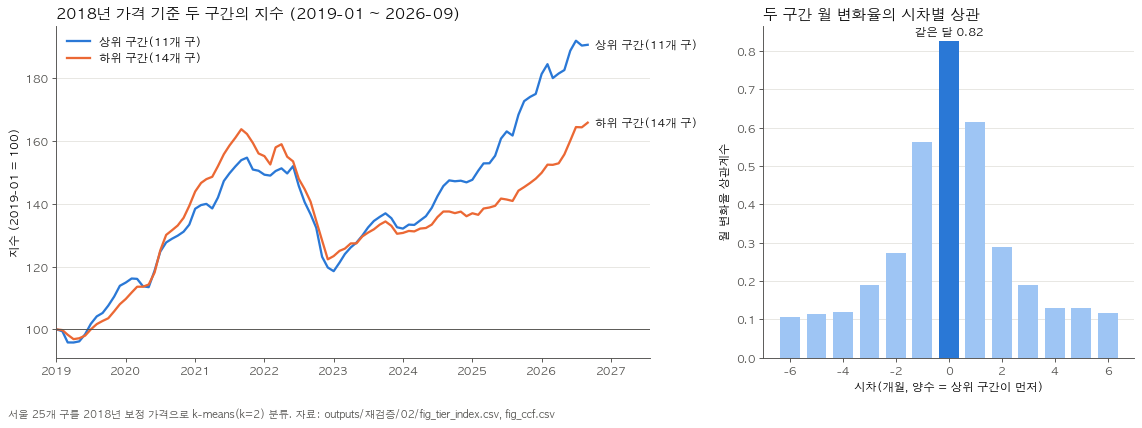

In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["AppleGothic", "NanumGothic", "Malgun Gothic"]:
    if _name in _fonts:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # 범주 색 고정 순서
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"


def style(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK2)
    ax.tick_params(colors=INK2)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name):
    """폭 1200px 이하 PNG로 저장하고 노트북에 표시한다(이 노트북은 Agg 백엔드라 plt.show()로는 보이지 않음)."""
    from IPython.display import Image, display
    w = fig.get_size_inches()[0]
    fig.savefig(OUT / name, dpi=min(110, 1150 / w), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / name)))

OUT = ROOT / "outputs" / "재검증" / "02"
t = pd.read_csv(OUT / "fig_tier_index.csv")
t = t[t["k"] == 2].copy()
t["date"] = pd.to_datetime(t["month"])
cc = pd.read_csv(OUT / "fig_ccf.csv")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.6, 1]})
names = {1: "상위 구간", 2: "하위 구간"}
for tier, g in t.groupby("tier"):
    lab = f"{names[tier]}({g['n_gu'].iloc[0]}개 구)"
    a1.plot(g["date"], g["index"], color=SERIES[tier - 1], lw=2, label=lab)
    a1.annotate(lab, (g["date"].iloc[-1], g["index"].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=10, color=INK)
a1.axhline(100, color=INK2, lw=0.8)
a1.set_xlim(t["date"].min(), t["date"].max() + pd.Timedelta(days=330))
a1.xaxis.set_major_locator(mdates.YearLocator())
a1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
a1.set_ylabel("지수 (2019-01 = 100)")
a1.set_title("2018년 가격 기준 두 구간의 지수 (2019-01 ~ 2026-09)", loc="left", fontsize=13, color=INK)
a1.legend(loc="upper left", frameon=False)
style(a1)

colors = [SERIES[0] if l == 0 else "#9ec5f4" for l in cc["lag"]]
a2.bar(cc["lag"], cc["corr"], color=colors, width=0.75)
a2.axhline(0, color=INK2, lw=0.8)
c0 = cc.loc[cc["lag"] == 0, "corr"].iat[0]
a2.annotate(f"같은 달 {c0:.2f}", (0, c0), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=10, color=INK)
a2.set_xticks(range(-6, 7, 2))
a2.set_xlabel("시차(개월, 양수 = 상위 구간이 먼저)")
a2.set_ylabel("월 변화율 상관계수")
a2.set_title("두 구간 월 변화율의 시차별 상관", loc="left", fontsize=13, color=INK)
style(a2)
fig.text(0.01, -0.03, "서울 25개 구를 2018년 보정 가격으로 k-means(k=2) 분류. 자료: outputs/재검증/02/fig_tier_index.csv, fig_ccf.csv",
         fontsize=9, color=INK2)
fig.tight_layout()
save(fig, "viz_02_tiers_together.png")
